# Vulkan HoloViz Ecosystem Demo (`vknumpy` + `vkpandas` + `vkspatial` + `vkshader` + `vkholoviews` + `vkpanel`)

Declarative `*` Overlay, `+` Layout, `.opts()`, GPU `datashade()`, GPU `Histogram`, `Bars`, `Curve`, GPU `vkspatial` point-in-polygon & 2D Morton spatial indexing, and reactive `vkpanel` dashboards on **11.84M real NYC Taxi trips**.

In [1]:
import sys, time
from pathlib import Path

_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
for _p in (_root, _root.parent / "vkshader", _root.parent / "vkpandas", _root.parent / "delightful-hertz"):
    if _p.is_dir() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import vknumpy as vnp
import vkpandas as vpd
import vkholoviews as hv

parquet = Path.home() / ".cache/hvsampledata/nyc_taxi/v2/nyc_taxi_wide.parq"
t0 = time.perf_counter()
df = vpd.read_parquet(parquet, columns=["pickup_x", "pickup_y", "fare_amount", "tip_amount", "pickup_hour"])
df["pickup_hour"] = df["pickup_hour"].astype(vnp.int32)
print(f"Loaded {len(df):,} trips into GPU vkpandas in {time.perf_counter() - t0:.2f}s")

Loaded 11,842,094 trips into GPU vkpandas in 0.49s


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


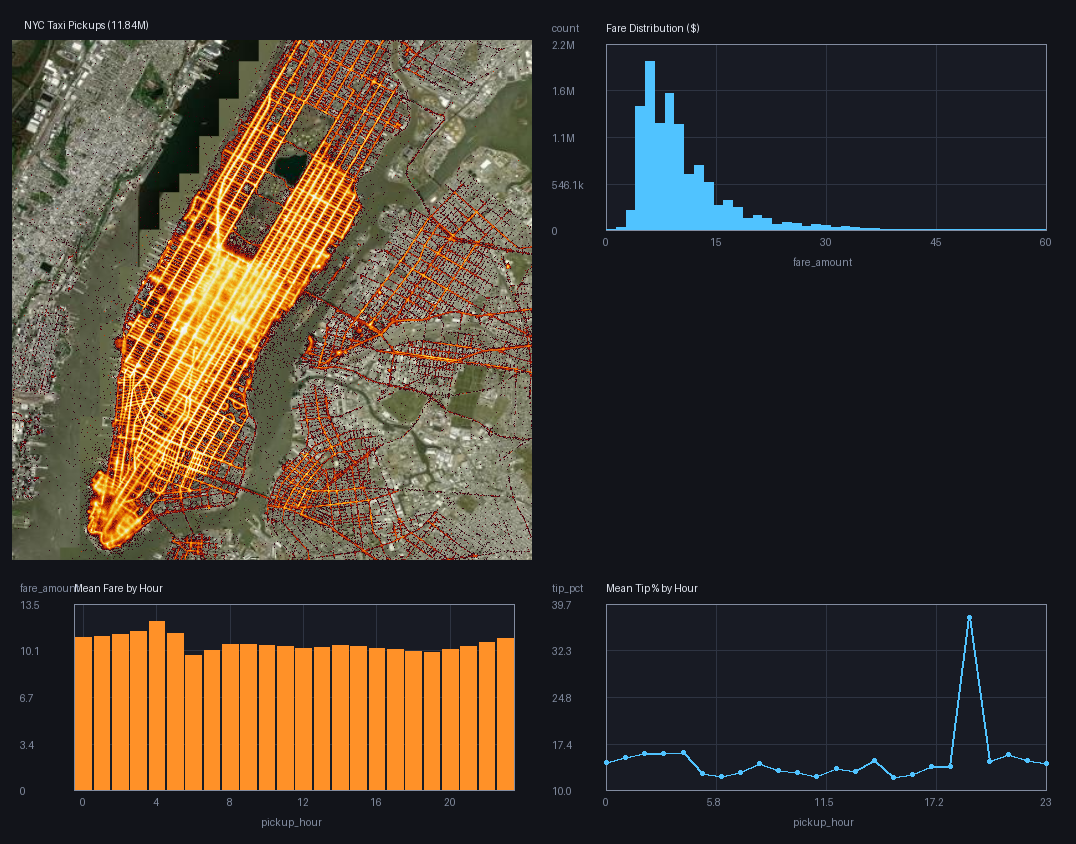

In [2]:
clean = df[df["fare_amount"] > 0.0]
clean["tip_pct"] = (clean["tip_amount"] / clean["fare_amount"]) * 100.0
by_hour = clean[["pickup_hour", "fare_amount", "tip_pct"]].groupby("pickup_hour").mean()

taxi_map = (
    hv.Tiles("esri")
    * hv.datashade(hv.Points(df, ["pickup_x", "pickup_y"]), how="eq_hist")
).opts(width=520, height=520, xlim=(-8242000, -8226000), ylim=(4968000, 4985000), title="NYC Taxi Pickups (11.84M)")

fare_hist = hv.Histogram(clean, "fare_amount", bins=45, range=(0, 60)).opts(width=520, height=260, title="Fare Distribution ($)")
hourly_fare = hv.Bars(by_hour, "pickup_hour", "fare_amount").opts(width=520, height=260, title="Mean Fare by Hour")
hourly_tip = hv.Curve(by_hour, "pickup_hour", "tip_pct").opts(width=520, height=260, title="Mean Tip % by Hour")

(taxi_map + fare_hist + hourly_fare + hourly_tip).cols(2)

In [3]:
# Live linked cross-filtering + GPU dynspread: panning/zooming the map
# recomputes the Fare & Tip histograms for ONLY the visible viewport in VRAM (~5 ms)!
linked_fare = hv.Histogram(df, "fare_amount", bins=40, range=(0, 60)).opts(width=420, height=280, title="Viewport Fare ($)")
linked_tip  = hv.Histogram(df, "tip_amount",  bins=40, range=(0, 15)).opts(width=420, height=280, title="Viewport Tip ($)")

(taxi_map.opts(width=600, height=600) + linked_fare + linked_tip).interact();

## GPU Geospatial Analysis & Reactive Dashboard (`vkspatial` + `vkpanel`)

- **`vkspatial.lonlat_to_mercator`**: projects WGS84 neighborhood polygons & landmarks to Web Mercator on GPU.
- **`vkspatial.point_in_polygon`**: zero-copy Vulkan SPIR-V ray-casting across all **11.84M** taxi pickups.
- **`vkspatial.GeoDataFrame.pack_partitions(256)`**: sorts trips on GPU along a 2D Morton (Z-order) space-filling curve for fast partition-pruned `within_polygon()` and `radius_query()` lookups.
- **`vkpanel`**: HoloViz Panel-style `Select`, `IntSlider`, `Tabs`, `Card`, `DataTable`, and `pn.bind(...)` reactive dashboard.

In [4]:
import numpy as np
import vkspatial as vks
import vkpanel as pn

# Real NYC neighborhood polygons in WGS84 (lon, lat) degrees
NYC_ZONES_LONLAT = {
    "Midtown Manhattan": [
        (-74.0020, 40.7484), (-73.9675, 40.7484),
        (-73.9610, 40.7685), (-73.9935, 40.7685),
    ],
    "Financial District": [
        (-74.0185, 40.7005), (-74.0010, 40.7015),
        (-74.0000, 40.7145), (-74.0165, 40.7155),
    ],
    "SoHo & Greenwich Village": [
        (-74.0105, 40.7195), (-73.9905, 40.7195),
        (-73.9880, 40.7395), (-74.0095, 40.7395),
    ],
    "Upper East Side": [
        (-73.9735, 40.7645), (-73.9445, 40.7645),
        (-73.9410, 40.7855), (-73.9595, 40.7855),
    ],
    "Upper West Side": [
        (-73.9930, 40.7685), (-73.9735, 40.7685),
        (-73.9600, 40.7935), (-73.9825, 40.7935),
    ],
}

def _poly_to_mercator(lonlat_ring):
    lons = np.array([p[0] for p in lonlat_ring], dtype=np.float32)
    lats = np.array([p[1] for p in lonlat_ring], dtype=np.float32)
    mx, my = vks.lonlat_to_mercator(lons, lats)
    return np.column_stack([mx.to_numpy(), my.to_numpy()]).astype(np.float32)

NYC_ZONES = {name: _poly_to_mercator(ring) for name, ring in NYC_ZONES_LONLAT.items()}

# Benchmark zero-copy GPU point_in_polygon across all 11.84M trips
rows = {"Neighborhood": [], "Trips": [], "Share (%)": [], "Mean Fare ($)": [], "Mean Tip ($)": [], "GPU PIP (ms)": []}
total_n = len(df)
for name, poly in NYC_ZONES.items():
    t0 = time.perf_counter()
    mask = vks.point_in_polygon(df["pickup_x"], df["pickup_y"], poly)
    pip_ms = (time.perf_counter() - t0) * 1000.0
    sub = df[mask]
    n_hits = len(sub)
    rows["Neighborhood"].append(name)
    rows["Trips"].append(f"{n_hits:,}")
    rows["Share (%)"].append(round(100.0 * n_hits / total_n, 2))
    rows["Mean Fare ($)"].append(round(float(sub["fare_amount"].mean()), 2) if n_hits else 0.0)
    rows["Mean Tip ($)"].append(round(float(sub["tip_amount"].mean()), 2) if n_hits else 0.0)
    rows["GPU PIP (ms)"].append(round(pip_ms, 1))

pn.Card(pn.DataTable(rows, max_rows=10), title="NYC Neighborhood Pickups — Zero-Copy GPU point_in_polygon (11.84M trips)")

In [5]:
# Build a 2D Morton Z-order partitioned GPU GeoDataFrame for instant polygon & radius queries
t0 = time.perf_counter()
gdf = vks.GeoDataFrame(clean, x="pickup_x", y="pickup_y").pack_partitions(npartitions=256)
print(f"Packed {len(gdf):,} trips into {len(gdf._partitions)} GPU Morton partitions in {time.perf_counter() - t0:.2f}s")

NYC_LANDMARKS_LONLAT = {
    "Times Square": (-73.9855, 40.7580),
    "Central Park South": (-73.9772, 40.7654),
    "Wall Street / NYSE": (-74.0113, 40.7069),
    "Empire State Building": (-73.9857, 40.7484),
    "Penn Station": (-73.9935, 40.7506),
    "Brooklyn Bridge": (-73.9969, 40.7061),
}
NYC_LANDMARKS = {}
for _name, (_lon, _lat) in NYC_LANDMARKS_LONLAT.items():
    _mx, _my = vks.lonlat_to_mercator(np.array([_lon], dtype=np.float32), np.array([_lat], dtype=np.float32))
    NYC_LANDMARKS[_name] = (float(_mx.to_numpy()[0]), float(_my.to_numpy()[0]))

# Tab 1: Interactive Neighborhood Polygon Explorer
zone_select = pn.Select(name="Neighborhood", options=list(NYC_ZONES.keys()), value="Midtown Manhattan")

def _zone_view(zone_name):
    t0 = time.perf_counter()
    sub = gdf.within_polygon(NYC_ZONES[zone_name])
    q_ms = (time.perf_counter() - t0) * 1000.0
    mean_fare = float(sub["fare_amount"].mean()) if len(sub) else 0.0
    mean_tip = float(sub["tip_pct"].mean()) if len(sub) else 0.0
    return hv.Histogram(sub, "fare_amount", bins=40, range=(0, 60)).opts(
        width=560, height=280,
        title=f"{zone_name}: {len(sub):,} trips | Fare ${mean_fare:.2f} | Tip {mean_tip:.1f}% ({q_ms:.0f} ms)",
    )

zone_tab = pn.Column(zone_select, pn.bind(_zone_view, zone_select))

# Tab 2: Interactive Landmark Radius Query Explorer
landmark_select = pn.Select(name="Landmark", options=list(NYC_LANDMARKS.keys()), value="Times Square")
radius_slider = pn.IntSlider(name="Radius (m)", start=150, end=1500, step=50, value=400)

def _radius_hist(landmark_name, radius_m):
    cx, cy = NYC_LANDMARKS[landmark_name]
    t0 = time.perf_counter()
    hits = gdf.radius_query(cx, cy, float(radius_m))
    q_ms = (time.perf_counter() - t0) * 1000.0
    mean_fare = float(hits["fare_amount"].mean()) if len(hits) else 0.0
    mean_tip = float(hits["tip_amount"].mean()) if len(hits) else 0.0
    return hv.Histogram(hits, "fare_amount", bins=35, range=(0, 60)).opts(
        width=560, height=260,
        title=f"{landmark_name} (r={radius_m}m): {len(hits):,} trips | Fare ${mean_fare:.2f} | Tip ${mean_tip:.2f} ({q_ms:.0f} ms)",
    )

def _radius_table(landmark_name, radius_m):
    cx, cy = NYC_LANDMARKS[landmark_name]
    hits = gdf.radius_query(cx, cy, float(radius_m), max_hits=8)
    return hits[["pickup_hour", "fare_amount", "tip_amount", "tip_pct"]]

radius_tab = pn.Column(
    pn.Row(landmark_select, radius_slider),
    pn.bind(_radius_hist, landmark_select, radius_slider),
    pn.bind(_radius_table, landmark_select, radius_slider),
)

pn.Tabs(("Neighborhood Polygons", zone_tab), ("Landmark Radius Query", radius_tab))

[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Packed 11,836,806 trips into 256 GPU Morton partitions in 3.60s
